In [1]:
import geojson
import geopandas as gpd
import rasterio
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import firedrake
from firedrake import Constant, inner, jump, grad, dx, avg, dS, min_value, max_value, conditional, pi, assemble
import icepack
from matplotlib.colors import LinearSegmentedColormap
import irksome
from irksome import Dt
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator, FormatStrFormatter)
import matplotlib.colors as col
from tqdm.notebook import trange, tqdm
from functools import partial


In [2]:
def subplots(obs1, transform, window, *args, **kwargs):
    fig, axes = plt.subplots(figsize = (10,8))
    xmin, ymin, xmax, ymax = rasterio.windows.bounds(window, transform)
    extent = (xmin, xmax, ymin, ymax)
    plot = axes.imshow(
        obs1, 
        cmap="Blues_r", 
        extent=extent
    )
    fig.colorbar(plot,                       
                      orientation = 'vertical', 
                      shrink=0.65, 
                      pad = 0.01, 
                      aspect=50)

    return fig, axes

def fix_obs(field, file):
    ny, nx = field.shape
    bound_loc = file.bounds
    
    xh = np.linspace(bound_loc.left, bound_loc.right, nx)
    yh = np.linspace(bound_loc.bottom, bound_loc.top, ny)[::-1]

    return xr.DataArray(
        field,
        dims=("y", "x"),
        coords={"x": xh, "y": yh},
    )

def regularization(h):
    Θ = firedrake.Constant(1.0)
    L = firedrake.Constant(1.0e2)
    γ = firedrake.Constant(1.0e3)
    area = Constant(assemble(Constant(1.0) * dx(mesh)))
    
    r_1 = (
        0.5 / area
        * (L / Θ)**2
        * firedrake.inner(firedrake.grad(h), firedrake.grad(h))
        * firedrake.dx(domain=mesh))
    
    r_2 = γ / area * min_value(0, h) ** 2 * dx(domain=mesh)
    
    return r_1 + r_2

## Reading in relevant files
Outline, thickness, bed profile

In [3]:
home_dir = '../data/'

outline_fn = home_dir + 'emmons_outine/emmons_1896_mod.geojson'

m1_h = home_dir + 'Thickness/m1-thickness_RGI60-02.14297.tif'
m2_h = home_dir + 'Thickness/m2-thickness_RGI60-02.14297.tif'
m3_h = home_dir + 'Thickness/m3-thickness_RGI60-02.14297.tif'

dave_bed = home_dir + 'surfaces/clipped_bed_dave.tif' 

In [4]:
with open(outline_fn, "r") as outline_file:
    outline = geojson.load(outline_file)

In [5]:
δ = 0.0

coords = np.array(list(geojson.utils.coords(outline)))
xmin, xmax = coords[:, 0].min() - δ, coords[:, 0].max() + δ
ymin, ymax = coords[:, 1].min() - δ, coords[:, 1].max() + δ

print(f'Outline Bbox: left={xmin}, bottom={ymin}, right={xmax}, top={ymax}')

Outline Bbox: left=594790.788972, bottom=5188892.145092, right=601987.779641, top=5195038.951454


## Thickness Data

In [6]:
# Thickness File (Farinotti)
m2_file = rasterio.open(m2_h, 'r')
h_transform = m2_file.transform
bounds = m2_file.bounds

h_window = rasterio.windows.from_bounds(
    *bounds, 
    transform=h_transform
).round_lengths().round_offsets()

m2_obs = m2_file.read(indexes=1, window = h_window, masked = True)

In [7]:
m1_file = rasterio.open(m1_h, 'r')
h1_transform = m1_file.transform
bounds1 = m1_file.bounds

h1_window = rasterio.windows.from_bounds(
    *bounds1, 
    transform=h1_transform
).round_lengths().round_offsets()

m1_obs = m1_file.read(indexes=1, window = h1_window, masked = True)

In [8]:
m3_file = rasterio.open(m3_h, 'r')
h3_transform = m3_file.transform
bounds3 = m3_file.bounds

h3_window = rasterio.windows.from_bounds(
    *bounds3, 
    transform=h3_transform
).round_lengths().round_offsets()

m3_obs = m3_file.read(indexes=1, window = h3_window, masked = True)

In [9]:
# Error calculation from inter model varience
N = 3

m_avg = m1_obs + m2_obs + m3_obs / N
m_σ = (
      ((m1_obs - m_avg) ** 2 
    + (m2_obs - m_avg) ** 2
    + (m3_obs - m_avg) ** 2) / N) ** 0.5

## Bed Data

In [10]:
bed_file = rasterio.open(dave_bed, 'r')

transform = bed_file.transform
window = rasterio.windows.from_bounds(
    left=xmin, bottom=ymin, right=xmax, top=ymax, transform=transform
).round_lengths().round_offsets()

b_obs = bed_file.read(indexes=1, window=window, masked = True)
b_obs[b_obs < 0] = 0

## Generate Mesh

In [11]:
gmsh_mesh = icepack.meshing.collection_to_gmsh(outline)
gmsh_mesh.write("emmons.msh", verbose=False)

mesh = firedrake.Mesh("emmons.msh") # Initial mesh

In [12]:
from firedrake.mg.mesh import MeshHierarchy

mesh0 = firedrake.Mesh('emmons.msh')
hierarchy = MeshHierarchy(mesh0, 3, 1) 
mesh = hierarchy[1] 

In [29]:
cell_sizes = mesh.cell_sizes.dat.data_ro

print(f'Cells: {mesh.num_cells()}')
print(f'Min: {cell_sizes.min()} m')
print(f'Max: {cell_sizes.max()} m')
print(f'Avg: {cell_sizes.mean()} m')
print(f'Vertices: {mesh.num_vertices()}')

Cells: 960
Min: 66.44252575808679 m
Max: 512.0249656666597 m
Avg: 228.10928398803557 m
Vertices: 527


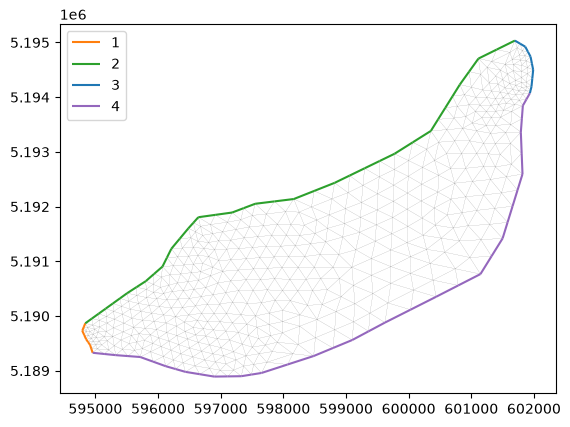

In [14]:
fig, axes = plt.subplots()
kw = {
    "boundary_kw": {"colors": ["tab:orange", "tab:green", "tab:blue", "tab:purple"]},
    "interior_kw": {"linewidth": 0.03},
}
firedrake.triplot(mesh, axes=axes, **kw);
axes.legend(loc="upper left");

In [15]:
dg0 = firedrake.FiniteElement("DG", "triangle", 0)
dg1 = firedrake.FiniteElement("DG", "triangle", 1)
cg1 = firedrake.FiniteElement("CG", "triangle", 1)

V = firedrake.VectorFunctionSpace(mesh, cg1)
Q = firedrake.FunctionSpace(mesh, cg1) 

## Thickness Data Fix
Not fitting (less formal method)
needs to be regularized 

In [16]:
m2 = fix_obs(m2_obs, m2_file)
h_interp = icepack.interpolate(m2, Q)

h_interp.dat.data[:] = np.nan_to_num(h_interp.dat.data[:], nan=0.0) # Find+replace NaNs in interpolated field 

## Bed Interpolation

In [17]:
def gridded_to_point_set(raster):
    f_input = firedrake.Function(Δ_input)
    f_input.dat.data[:] = raster[indices[:, 1], indices[:, 0]]
    f_output = firedrake.Function(Δ)
    f_output.interpolate(f_input)
    return f_output

In [18]:
xs = np.array(
    [
        transform * (i, j)
        for i in range(window.width) # 'window' only works for bed, for h use 'h_window'
        for j in range(window.height)
    ]
)

In [19]:
indices = np.array(
    [
        (i, j)
        for i in range(window.width)
        for j in range(window.height)
        if (
            mesh.locate_cell(transform * (i, j))
        )
    ]
)
xs = np.array([transform * idx for idx in indices])

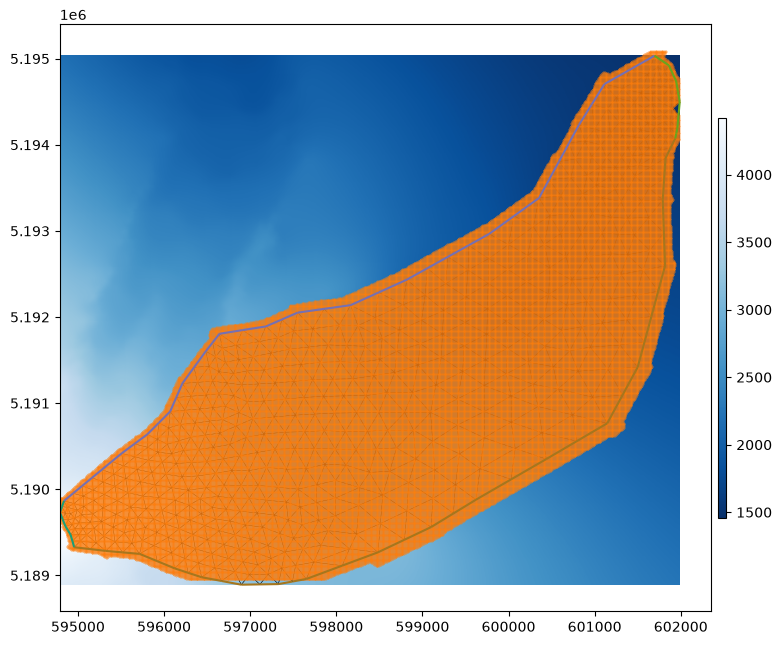

In [20]:
fig, axes = subplots(b_obs, transform, window)
firedrake.triplot(mesh, axes=axes, interior_kw={"linewidth": 0.25})
axes.scatter(xs[:, 0], xs[:, 1], 0.05, "tab:orange");

In [21]:
point_set = firedrake.VertexOnlyMesh(
    mesh, 
    xs, 
    missing_points_behaviour="error",
    reorder = False
)

Δ_input = firedrake.FunctionSpace(point_set.input_ordering, "DG", 0)
Δ = firedrake.FunctionSpace(point_set, "DG", 0)

In [22]:
b_o = gridded_to_point_set(b_obs)

h_min = 1
b_σ = firedrake.Function(Δ).interpolate(max_value(0.16 * h_interp, h_min))

In [23]:
b_fitted = icepack.fit(b_o, b_σ, 200, Q)

b_slope = firedrake.grad(b_fitted)
b_slopeProj = icepack.interpolate(b_slope, V)

In [24]:
s_calc = icepack.interpolate(h_interp + b_fitted, Q)

slope = firedrake.grad(s_calc)
slope_proj = icepack.interpolate(slope, V)

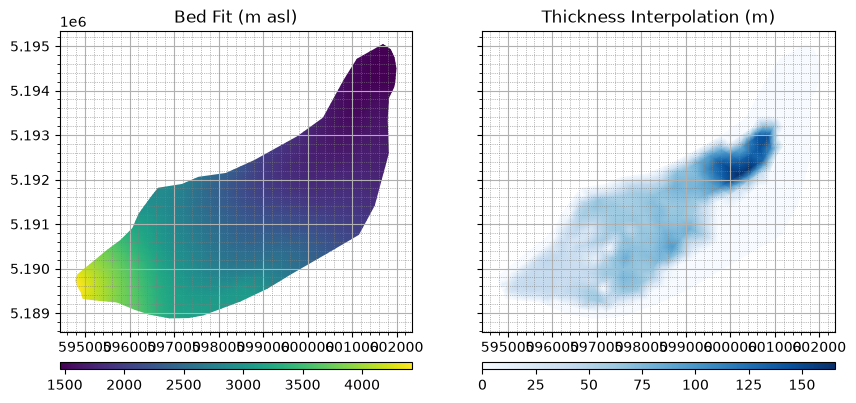

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(10, 10), sharey = True)

# Bed
colors = firedrake.tripcolor(
    b_fitted,
    #vmin = 0,
    axes=ax[0],
)
fig.colorbar(colors, location="bottom", fraction=0.046, pad=0.04, aspect=50)

ax[0].set_aspect("equal")
ax[0].set_title("Bed Fit (m asl)")
ax[0].xaxis.set_minor_locator(AutoMinorLocator())
ax[0].yaxis.set_minor_locator(AutoMinorLocator())
ax[0].tick_params(which="both")
ax[0].grid()
ax[0].grid(which="minor", linestyle=":", linewidth=0.5, color="gray")

# Thickness
colors = firedrake.tripcolor(
    h_interp,
    vmin = 0,
    cmap="Blues",
    axes=ax[1],
)
fig.colorbar(colors, location="bottom", fraction=0.046, pad=0.04, aspect=50)

ax[1].set_aspect("equal")
ax[1].set_title("Thickness Interpolation (m)")
ax[1].xaxis.set_minor_locator(AutoMinorLocator())
ax[1].yaxis.set_minor_locator(AutoMinorLocator())
ax[1].tick_params(which="both")
ax[1].grid()
ax[1].grid(which="minor", linestyle=":", linewidth=0.5, color="gray")

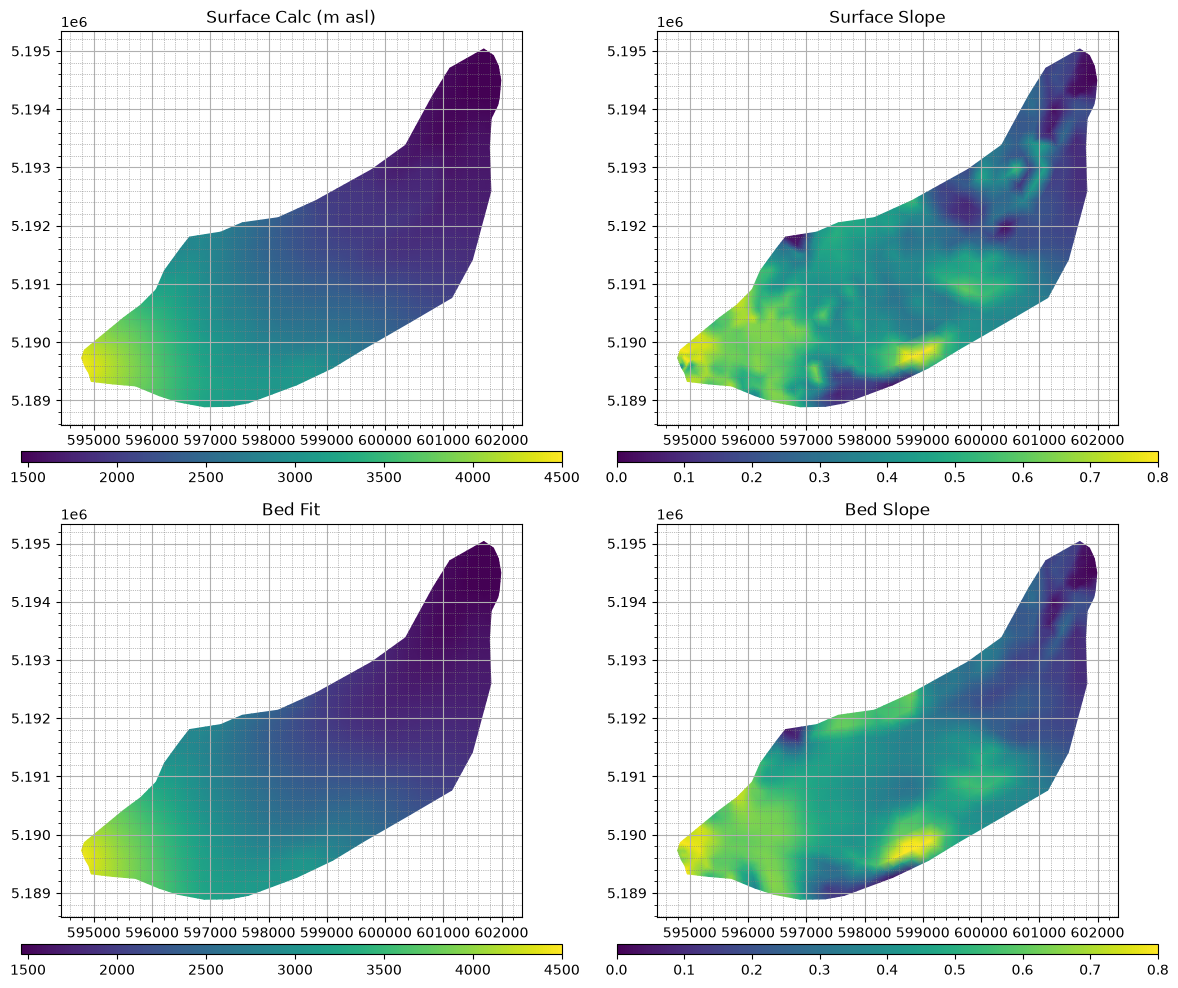

In [26]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

colors = firedrake.tripcolor(
    s_calc,
    #vmin = 0,
    vmax = 4500,
    axes=ax[0, 0],
)
fig.colorbar(colors, location="bottom", fraction=0.046, pad=0.06, aspect=50)

ax[0, 0].set_aspect("equal")
ax[0, 0].set_title("Surface Calc (m asl)")
ax[0, 0].xaxis.set_minor_locator(AutoMinorLocator())
ax[0, 0].yaxis.set_minor_locator(AutoMinorLocator())
ax[0, 0].tick_params(which="both")
ax[0, 0].grid()
ax[0, 0].grid(which="minor", linestyle=":", linewidth=0.5, color="gray")

colors = firedrake.tripcolor(
    slope_proj,
    vmin = 0,
    vmax = 0.8,
    axes=ax[0, 1],
)
fig.colorbar(colors, location="bottom", fraction=0.046, pad=0.06, aspect=50)

ax[0, 1].set_aspect("equal")
ax[0, 1].set_title("Surface Slope")
ax[0, 1].xaxis.set_minor_locator(AutoMinorLocator())
ax[0, 1].yaxis.set_minor_locator(AutoMinorLocator())
ax[0, 1].tick_params(which="both")
ax[0, 1].grid()
ax[0, 1].grid(which="minor", linestyle=":", linewidth=0.5, color="gray")

colors = firedrake.tripcolor(
    b_fitted,
    #vmin = 0,
    vmax = 4500,
    axes=ax[1, 0],
)
fig.colorbar(colors, location="bottom", fraction=0.046, pad=0.06, aspect=50)

ax[1, 0].set_aspect("equal")
ax[1, 0].set_title("Bed Fit")
ax[1, 0].xaxis.set_minor_locator(AutoMinorLocator())
ax[1, 0].yaxis.set_minor_locator(AutoMinorLocator())
ax[1, 0].tick_params(which="both")
ax[1, 0].grid()
ax[1, 0].grid(which="minor", linestyle=":", linewidth=0.5, color="gray")

colors = firedrake.tripcolor(
    b_slopeProj,
    vmin = 0,
    vmax = 0.8,
    axes=ax[1, 1],
)
fig.colorbar(colors, location="bottom", fraction=0.046, pad=0.06, aspect=50)

ax[1, 1].set_aspect("equal")
ax[1, 1].set_title("Bed Slope")
ax[1, 1].xaxis.set_minor_locator(AutoMinorLocator())
ax[1, 1].yaxis.set_minor_locator(AutoMinorLocator())
ax[1, 1].tick_params(which="both")
ax[1, 1].grid()
ax[1, 1].grid(which="minor", linestyle=":", linewidth=0.5, color="gray")

plt.tight_layout()

In [27]:
filename = "notebooks/Checkpoints/emmmons_initialization_200m.h5"
with firedrake.CheckpointFile(filename, "w") as checkpoint:
    checkpoint.save_mesh(mesh)
    checkpoint.save_function(h_interp, name="thickness")
    checkpoint.save_function(b_fitted, name="bed")
    checkpoint.save_function(s_calc, name="surface")    